data file

https://universe.roboflow.com/brad-dwyer/pothole-voxrl

In [ ]:
import sys
import subprocess

# ultralytics 패키지 자동 설치 및 로드
try:
    import ultralytics
except ImportError:
    print("📦 ultralytics 패키지 설치 중...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "tabulate"])
    print("✅ 설치 완료!")

import os
import shutil
import torch
import pandas as pd
from ultralytics import YOLO
from sklearn.model_selection import train_test_split
import glob
from google.colab import drive # Added import for drive

# 1. 구글 드라이브 마운트
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_DATA_DIR = "/content/Pothole_Local_811"

# 2. 모든 이미지 및 라벨 수집
all_images = glob.glob(os.path.join(DRIVE_DATA_DIR, "*/**/images/*.*"), recursive=True)
all_images = [f for f in all_images if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]

print(f"📸 수집된 전체 이미지 수: {len(all_images)}장")

# 3. 8:1:1 비율 분할 (Train 80%, Valid 10%, Test 10%)
train_imgs, val_test_imgs = train_test_split(all_images, test_size=0.20, random_state=42)
val_imgs, test_imgs = train_test_split(val_test_imgs, test_size=0.50, random_state=42)

splits = {'train': train_imgs, 'valid': val_imgs, 'test': test_imgs}

# 4. 로컬 SSD로 파일 이관
if os.path.exists(LOCAL_DATA_DIR):
    shutil.rmtree(LOCAL_DATA_DIR)

for split_name, img_list in splits.items():
    img_dst_dir = os.path.join(LOCAL_DATA_DIR, split_name, "images")
    lbl_dst_dir = os.path.join(LOCAL_DATA_DIR, split_name, "labels")
    os.makedirs(img_dst_dir, exist_ok=True)
    os.makedirs(lbl_dst_dir, exist_ok=True)

    for img_path in img_list:
        shutil.copy2(img_path, img_dst_dir)
        # 동일 파일명의 txt 라벨 복사
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(os.path.dirname(os.path.dirname(img_path)), "labels", base_name + ".txt")
        if os.path.exists(lbl_path):
            shutil.copy2(lbl_path, lbl_dst_dir)

# 5. data.yaml 자동 생성
yaml_path = os.path.join(LOCAL_DATA_DIR, "data.yaml")
yaml_content = f"""
path: {LOCAL_DATA_DIR}
train: train/images
val: valid/images
test: test/images

c: 1
names: ['pothole']
""".strip()

with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print(f"✅ 8:1:1 분할 완료! (Train: {len(train_imgs)}장 | Valid: {len(val_imgs)}장 | Test: {len(test_imgs)}장)")

📦 ultralytics 패키지 설치 중...
✅ 설치 완료!
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive
📸 수집된 전체 이미지 수: 665장
✅ 8:1:1 분할 완료! (Train: 532장 | Valid: 66장 | Test: 67장)


In [ ]:
import os
from ultralytics import YOLO

# 경로 설정
YAML_PATH = "/content/Pothole_Local_811/data.yaml"
DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"

# YOLOv8 3개 모델 체급 동시 목표 상향 학습 설정 (Training Infrastructure 재구축)
target_models = [
    {"weights": "yolov8n.pt", "name": "yolov8n_target85_final", "batch": 16},
    {"weights": "yolov8s.pt", "name": "yolov8s_target85_final", "batch": 16},
    {"weights": "yolov8m.pt", "name": "yolov8m_target85_final", "batch": 8}   # M 모델 메모리 방지용 배치 8
]

for config in target_models:
    print(f"\n🚀 [{config['name']}] 고해상도 및 인프라 최적화 학습 시작 ({config['weights']})")
    model = YOLO(config["weights"])

    # 훈련 인프라 세팅 적용
    model.train(
        data=YAML_PATH,
        epochs=100,            # 충분한 수렴을 위한 100 에폭 설정
        imgsz=1024,          # 고해상도 적용 (소형 포트홀 Recall 개선)
        batch=config["batch"],

        # 최적화 및 스케줄러 설정
        optimizer="AdamW",
        lr0=0.001,
        lrf=0.01,
        weight_decay=0.0005,
        cos_lr=True,
        warmup_epochs=3.0,
        close_mosaic=15,     # 마지막 15 에폭에서 모자이크 종료

        # 실질적 날씨/환경 모사 증강 적용
        scale=0.6,
        hsv_h=0.015,
        hsv_s=0.7,
        hsv_v=0.4,           # 명도 변화 (그림자, 야간, 젖은 노면 대응)
        erasing=0.4,         # 무작위 영역 가리기 (과적합 방지)
        fliplr=0.5,

        project=os.path.join(DRIVE_DATA_DIR, "runs"),
        name=config["name"],
        exist_ok=True,
        device=0,
    )

# ========================================================
# 📌 TTA(Test-Time Augmentation) 적용 통합 검증
# ========================================================
print("\n🔍 TTA가 적용된 최종 모델 통합 검증 진행 중...")
for config in target_models:
    best_weights_path = os.path.join(DRIVE_DATA_DIR, "runs", config["name"], "weights", "best.pt")

    if os.path.exists(best_weights_path):
        val_model = YOLO(best_weights_path)
        # TTA(augment=True)와 보수적 임계값 적용으로 Precision과 Recall 동시 확보
        metrics = val_model.val(
            data=YAML_PATH,
            imgsz=1024,
            augment=True,      # TTA 활성화
            conf=0.15,         # 균형 잡힌 신뢰도 임계값
            iou=0.50,
            device=0
        )
        print(f"📊 [{config['name']}] 결과 -> Precision: {metrics.box.mp:.4f} | Recall: {metrics.box.mr:.4f} | mAP50: {metrics.box.map50:.4f}")


🚀 [yolov8n_target85_final] 고해상도 및 인프라 최적화 학습 시작 (yolov8n.pt)
Ultralytics 8.4.157 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/Pothole_Local_811/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.93

In [ ]:
import os
import shutil
import torch
import pandas as pd
from ultralytics import YOLO

# ========================================================
# 📌 1. 환경 설정 및 데이터 준비
# ========================================================
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_DATA_DIR = "/content/Pothole_Local"

# 구글 드라이브 ➔ Colab 로컬 SSD 데이터 복사
if not os.path.exists(LOCAL_DATA_DIR):
    print("🚚 구글 드라이브 데이터를 로컬 SSD로 복사 중...")
    shutil.copytree(DRIVE_DATA_DIR, LOCAL_DATA_DIR)
    print("✅ 데이터 로컬 복사 완료!")

# data.yaml 생성 및 경로 설정 (통일된 대문자 변수명 사용)
YAML_PATH = os.path.join(LOCAL_DATA_DIR, "data.yaml")
yaml_content = f"""
path: {LOCAL_DATA_DIR}
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['pothole']
""".strip()

with open(YAML_PATH, "w", encoding="utf-8") as f:
    f.write(yaml_content)


# ========================================================
# 📌 2. 모델 학습 (일반 최적화 & 강날씨 증강 학습)
# ========================================================
# (1) 기본 Target 85% Recall 최적화 학습
models_target85 = [
    {"weights": "yolov8n.pt", "name": "yolov8n_target85_optimized", "batch": 16},
    {"weights": "yolov8s.pt", "name": "yolov8s_target85_optimized", "batch": 16},
    {"weights": "yolov8m.pt", "name": "yolov8m_target85_optimized", "batch": 8}   # Medium 모델 OOM 방지
]

for config in models_target85:
    print(f"\n🚀 [{config['name']}] 학습 시작 ({config['weights']})")
    model = YOLO(config["weights"])
    model.train(
        data=YAML_PATH,
        epochs=150,
        imgsz=1024,
        batch=config["batch"],
        optimizer="AdamW",
        lr0=0.001,
        patience=40,
        cls=2.0,
        box=7.5,
        dfl=1.5,
        scale=0.5,
        erasing=0.1,
        mixup=0.0,
        close_mosaic=15,
        project=os.path.join(DRIVE_DATA_DIR, "runs"),
        name=config["name"],
        exist_ok=True,
        device=0,
    )

# (2) 강날씨/조명 증강 특화 학습
models_weather = [
    {"weights": "yolov8n.pt", "name": "yolov8n_weather_aug", "batch": 16},
    {"weights": "yolov8s.pt", "name": "yolov8s_weather_aug", "batch": 16},
    {"weights": "yolov8m.pt", "name": "yolov8m_weather_aug", "batch": 8}    # Medium 모델 OOM 방지
]

for config in models_weather:
    print(f"\n🚀 [{config['name']}] 강날씨/조명 증강 학습 시작...")
    model = YOLO(config["weights"])
    model.train(
        data=YAML_PATH,
        epochs=120,
        imgsz=800,
        batch=config["batch"],
        optimizer="AdamW",
        lr0=0.0015,
        patience=25,
        hsv_h=0.03,
        hsv_s=0.8,
        hsv_v=0.5,
        mixup=0.2,
        erasing=0.4,
        scale=0.6,
        degrees=0.0,
        flipud=0.0,
        fliplr=0.5,
        close_mosaic=15,
        project=os.path.join(DRIVE_DATA_DIR, "runs"),
        name=config["name"],
        exist_ok=True,
        device=0
    )


# ========================================================
# 📌 3. 전체 학습 모델 통합 검증 (conf=0.15)
# ========================================================
all_eval_models = [m["name"] for m in models_target85 + models_weather]
results_summary = []

for run_name in all_eval_models:
    best_weights_path = os.path.join(DRIVE_DATA_DIR, "runs", run_name, "weights", "best.pt")

    if os.path.exists(best_weights_path):
        print(f"🔍 [{run_name}] 검증 진행 중...")
        model = YOLO(best_weights_path)
        metrics = model.val(data=YAML_PATH, imgsz=800, conf=0.15, device=0, verbose=False)

        results_summary.append({
            "Model": run_name,
            "Precision": round(metrics.box.mp, 4),
            "Recall": round(metrics.box.mr, 4),
            "mAP50": round(metrics.box.map50, 4),
            "mAP50-95": round(metrics.box.map, 4)
        })
    else:
        print(f"⚠️ [{run_name}] 가중치 파일(best.pt)을 찾을 수 없습니다: {best_weights_path}")



# ========================================================
# 📌 4. 최적 모델 시각화 분석 파일 생성
# ========================================================
best_model_path = os.path.join(DRIVE_DATA_DIR, "runs/yolov8s_target85_optimized/weights/best.pt")
if os.path.exists(best_model_path):
    print("\n📸 최적 모델 시각화 검증 파일 생성 중...")
    model = YOLO(best_model_path)
    model.val(
        data=YAML_PATH,
        imgsz=800,
        conf=0.15,
        save_hybrid=True,
        project=os.path.join(DRIVE_DATA_DIR, "runs"),
        name="val_visual_analysis",
        device=0
    )


# ========================================================
# 📌 5. Conf / IoU 하이퍼파라미터 스위핑
# ========================================================
sweep_weights_path = os.path.join(DRIVE_DATA_DIR, "runs/yolov8n_high_recall/weights/best.pt")

if os.path.exists(sweep_weights_path):
    print("\n🔍 conf/iou 하이퍼파라미터 스위핑 진행 중...")
    model = YOLO(sweep_weights_path)
    sweep_results = []

    for conf in [0.01, 0.03, 0.05, 0.08, 0.10, 0.25, 0.3, 0.35]:
        for iou in [0.5, 0.6, 0.7]:
            metrics = model.val(data=YAML_PATH, imgsz=800, conf=conf, iou=iou, device=0, verbose=False)
            sweep_results.append({
                "conf": conf,
                "iou": iou,
                "Precision": round(metrics.box.mp, 4),
                "Recall": round(metrics.box.mr, 4),
                "mAP50": round(metrics.box.map50, 4)
            })

            df_res = pd.DataFrame(results_summary)
print("\n📊 [전체 모델 성능 비교표 (conf=0.15)]")
try:
    print(df_res.to_markdown(index=False))
except (ImportError, AttributeError):
    print(df_res.to_string(index=False))


    df_sweep = pd.DataFrame(sweep_results)
    print("\n📊 [yolov8n_high_recall conf/iou 스위핑 결과 (Recall 내림차순)]")
    try:
        print(df_sweep.sort_values(by="Recall", ascending=False).to_markdown(index=False))
    except (ImportError, AttributeError):
        print(df_sweep.sort_values(by="Recall", ascending=False).to_string(index=False))
else:
    print(f"\n⚠️ 스위핑 대상 가중치 파일(yolov8n_high_recall)이 존재하지 않아 스위핑을 건너땁니다.")

사용자님께서 제안하신 8:1:1 (Train:Valid:Test) 비율로 진행하기 위해서는, 현재 코드 내에는 명시적인 분할 스크립트가 없으므로
data.yaml 생성 전 데이터셋 폴더 구조를 직접 8:1:1로 재분배하는 코드를 추가하거나 수동으로 분할해야 합니다

Step 1. Test Dataset 독립 평가 및 추론 시각화
Validation Set으로만 측정된 결과를 확인했으므로, 학습에 전혀 관여하지 않은 Test Set(67장)으로 최종 검증을 수행하고 Bounding Box 추론 결과를 저장해야 합니다

In [ ]:
from ultralytics import YOLO

# 1. 가장 성능이 좋았던 YOLOv8m Best Weights 로드
best_model_path = "/content/drive/MyDrive/Pothole/runs/yolov8m_target85_optimized/weights/best.pt"
model = YOLO(best_model_path)

# 2. Test Set 독립 검증
test_results = model.val(
    data="/content/Pothole_Local_811/data.yaml",
    split="test",
    imgsz=1024
)

print(f"\n📊 [YOLOv8m Test Set 최종 성능]")
print(f" - mAP50    : {test_results.box.map50:.4f}")
print(f" - mAP50-95 : {test_results.box.map:.4f}")
print(f" - Precision: {test_results.box.mp:.4f}")
print(f" - Recall   : {test_results.box.mr:.4f}")

# 3. Test 이미지 Bounding Box 시각화 결과 Drive에 저장
model.predict(
    source="/content/Pothole_Local_811/test/images",
    save=True,
    conf=0.25,
    project="/content/drive/MyDrive/Pothole/runs",
    name="test_predictions",
    exist_ok=True
)
print("📸 Test 이미지 추론 및 시각화 결과가 Google Drive에 저장되었습니다.")

In [ ]:
import os
import pandas as pd
from ultralytics import YOLO

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
YAML_PATH = "/content/Pothole_Local/data.yaml"

WEIGHTS_PATH = os.path.join(DRIVE_DATA_DIR, "runs/yolov8m_cls3.5_enhanced/weights/best.pt")

if not os.path.exists(WEIGHTS_PATH):
    print(f"❌ 가중치 파일을 찾을 수 없습니다: {WEIGHTS_PATH}")
else:
    print("🔍 [yolov8m_cls3.5_enhanced] Low Conf/IoU 정밀 스위핑 진행 중...")
    model = YOLO(WEIGHTS_PATH)
    sweep_results = []

    # Recall 극대화를 위한 초저 Conf (0.005 ~ 0.05) 및 IoU 범위 탐색
    for conf in [0.005, 0.01, 0.02, 0.03, 0.05, 0.10]:
        for iou in [0.45, 0.50, 0.60]:
            metrics = model.val(data=YAML_PATH, imgsz=800, conf=conf, iou=iou, device=0, verbose=False)
            sweep_results.append({
                "conf": conf,
                "iou": iou,
                "Precision": round(metrics.box.mp, 4),
                "Recall": round(metrics.box.mr, 4),
                "mAP50": round(metrics.box.map50, 4),
                "mAP50-95": round(metrics.box.map, 4)
            })

    df_sweep = pd.DataFrame(sweep_results)
    print("\n📊 [cls3.5 가중치 기반 정밀 스위핑 결과 (Recall 내림차순)]")
    try:
        print(df_sweep.sort_values(by="Recall", ascending=False).to_markdown(index=False))
    except (ImportError, AttributeError):
        print(df_sweep.sort_values(by="Recall", ascending=False).to_string(index=False))

In [ ]:
import os
from ultralytics import YOLO

import os
from ultralytics import YOLO

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
YAML_PATH = "/content/Pothole_Local/data.yaml"

print("🚀 [yolov8m_cls5.0_extreme] 극한 손실 가중치(cls=5.0) 학습 시작...")
model = YOLO("yolov8m.pt")

model.train(
    data=YAML_PATH,
    epochs=120,
    imgsz=800,
    batch=8,           # Medium 모델 GPU OOM 방지
    optimizer="AdamW",
    lr0=0.001,
    patience=30,
    cls=5.0,           # 미탐지(FN) 벌점 극대화 (기본값 0.5 대비 10배 설정)
    box=7.5,
    dfl=1.5,
    hsv_h=0.03,
    hsv_s=0.8,
    hsv_v=0.5,
    mixup=0.2,
    erasing=0.4,
    close_mosaic=15,
    project=os.path.join(DRIVE_DATA_DIR, "runs"),
    name="yolov8m_cls5.0_extreme",
    exist_ok=True,
    device=0
)

In [ ]:
import os
import pandas as pd
from ultralytics import YOLO

# 1. 경로 설정 및 가중치 확인
DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
YAML_PATH = "/content/Pothole_Local/data.yaml"
WEIGHTS_PATH = os.path.join(DRIVE_DATA_DIR, "runs/yolov8m_cls5.0_extreme/weights/best.pt")

if not os.path.exists(WEIGHTS_PATH):
    print(f"❌ 가중치 파일을 찾을 수 없습니다: {WEIGHTS_PATH}")
else:
    print("🚀 [yolov8m_cls5.0_extreme] 해상도·TTA·임계값 통합 정밀 검증 시작...\n")
    model = YOLO(WEIGHTS_PATH)
    sweep_results = []

    # 2. 통합 스위핑 조건 설정 (해상도 800 vs 1024, TTA 여부, Conf/IoU)
    imgsz_list = [800, 1024]
    conf_list = [0.05, 0.10, 0.15, 0.25]
    iou_list = [0.45, 0.50]

    for imgsz in imgsz_list:
        for conf in conf_list:
            for iou in iou_list:
                # 일반 검증
                metrics = model.val(
                    data=YAML_PATH,
                    imgsz=imgsz,
                    conf=conf,
                    iou=iou,
                    device=0,
                    verbose=False
                )
                sweep_results.append({
                    "imgsz": imgsz,
                    "TTA": False,
                    "conf": conf,
                    "iou": iou,
                    "Precision": round(metrics.box.mp, 4),
                    "Recall": round(metrics.box.mr, 4),
                    "mAP50": round(metrics.box.map50, 4),
                    "mAP50-95": round(metrics.box.map, 4)
                })

    # 3. TTA (Test-Time Augmentation) 적용 검증 (Recall 극대화 실험)
    metrics_tta = model.val(
        data=YAML_PATH,
        imgsz=1024,
        conf=0.10,
        iou=0.45,
        augment=True,  # 멀티스케일 & 플립 추론
        device=0,
        verbose=False
    )
    sweep_results.append({
        "imgsz": 1024,
        "TTA": True,
        "conf": 0.10,
        "iou": 0.45,
        "Precision": round(metrics_tta.box.mp, 4),
        "Recall": round(metrics_tta.box.mr, 4),
        "mAP50": round(metrics_tta.box.map50, 4),
        "mAP50-95": round(metrics_tta.box.map, 4)
    })

    # 4. 종합 결과 출력 (Recall 내림차순 정렬)
    df_sweep = pd.DataFrame(sweep_results)
    print("📊 [통합 검증 및 스위핑 결과 (Recall 내림차순)]")
    try:
        print(df_sweep.sort_values(by="Recall", ascending=False).to_markdown(index=False))
    except (ImportError, AttributeError):
        print(df_sweep.sort_values(by="Recall", ascending=False).to_string(index=False))

    # 5. 최적 조건 시각화 분석 파일 저장 (Ground Truth vs Prediction)
    print("\n📸 미탐지 분석용 최종 시각화 이미지 생성 중...")
    model.val(
        data=YAML_PATH,
        imgsz=1024,
        conf=0.10,
        iou=0.45,
        save_hybrid=True,
        project=os.path.join(DRIVE_DATA_DIR, "runs"),
        name="val_final_visual_analysis",
        device=0
    )
    print("✅ 시각화 파일 저장 완료: /runs/val_final_visual_analysis")

In [ ]:
import os
import shutil
import pandas as pd
from ultralytics import YOLO

# ========================================================
# 📌 1. 경로 설정 및 파일 시스템 구글 드라이브 동기화 준비
# ========================================================
DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_DATA_DIR = "/content/Pothole_Local"
YAML_PATH = os.path.join(LOCAL_DATA_DIR, "data.yaml")
WEIGHTS_PATH = os.path.join(DRIVE_DATA_DIR, "runs/yolov8m_cls5.0_extreme/weights/best.pt")

# 로컬 임시 결과 저장 폴더 (Drive Errno 95 방지)
LOCAL_RUNS_DIR = "/content/runs"

if not os.path.exists(WEIGHTS_PATH):
    print(f"❌ 가중치 파일을 찾을 수 없습니다: {WEIGHTS_PATH}")
else:
    print("🚀 [yolov8m_cls5.0_extreme] 고해상도(1024) + TTA + Conf/IoU 통합 스위핑 시작...\n")
    model = YOLO(WEIGHTS_PATH)
    sweep_results = []

    # ========================================================
    # 📌 2. 해상도(800 vs 1024) x TTA(On/Off) x Conf/IoU 다차원 스위핑
    # ========================================================
    experiments_config = [
        # (imgsz, TTA 여부, Conf 리스트, IoU 리스트)
        (800, False, [0.05, 0.10, 0.15, 0.25], [0.45, 0.50]),
        (1024, False, [0.05, 0.10, 0.15, 0.25], [0.45, 0.50]),
        (1024, True,  [0.05, 0.10, 0.15],       [0.45, 0.50]) # TTA 적용 (Recall 극대화)
    ]

    for imgsz, use_tta, conf_list, iou_list in experiments_config:
        for conf in conf_list:
            for iou in iou_list:
                # 검증 수행
                metrics = model.val(
                    data=YAML_PATH,
                    imgsz=imgsz,
                    conf=conf,
                    iou=iou,
                    augment=use_tta,
                    device=0,
                    verbose=False
                )

                sweep_results.append({
                    "Resolution": imgsz,
                    "TTA": use_tta,
                    "Conf": conf,
                    "IoU": iou,
                    "Precision": round(metrics.box.mp, 4),
                    "Recall": round(metrics.box.mr, 4),
                    "mAP50": round(metrics.box.map50, 4),
                    "mAP50-95": round(metrics.box.map, 4)
                })

    # ========================================================
    # 📌 3. 종합 결과 비교표 출력 (Recall 내림차순 정렬)
    # ========================================================
    df_sweep = pd.DataFrame(sweep_results)
    print("📊 [고해상도 + TTA + 임계값 통합 스위핑 결과 (Recall 내림차순)]")
    try:
        print(df_sweep.sort_values(by=["Recall", "mAP50"], ascending=[False, False]).to_markdown(index=False))
    except (ImportError, AttributeError):
        print(df_sweep.sort_values(by=["Recall", "mAP50"], ascending=[False, False]).to_string(index=False))

    # 결과 CSV 구글 드라이브 저장
    df_sweep.to_csv(os.path.join(DRIVE_DATA_DIR, "integrated_sweeping_results.csv"), index=False, encoding="utf-8-sig")

    # ========================================================
    # 📌 4. 최적 조건 시각화 분석 파일 생성 (Ground Truth vs Prediction)
    # ========================================================
    print("\n📸 미탐지/오탐 분석용 Ground Truth 겹침 시각화 이미지 생성 중...")

    local_vis_dir = os.path.join(LOCAL_RUNS_DIR, "val_final_visual_analysis")
    drive_vis_dir = os.path.join(DRIVE_DATA_DIR, "runs", "val_final_visual_analysis")

    model.val(
        data=YAML_PATH,
        imgsz=1024,
        conf=0.10,
        iou=0.45,
        augment=True,       # TTA 활성화
        save_hybrid=True,   # GT와 예측값 함께 출력
        project=LOCAL_RUNS_DIR,
        name="val_final_visual_analysis",
        exist_ok=True,
        device=0
    )

    # 구글 드라이브 동기화
    if os.path.exists(local_vis_dir):
        if os.path.exists(drive_vis_dir):
            shutil.rmtree(drive_vis_dir)
        shutil.copytree(local_vis_dir, drive_vis_dir)
        print(f"✅ 시각화 이미지 구글 드라이브 동기화 완료: {drive_vis_dir}")

🚀 [yolov8m_cls5.0_extreme] 고해상도(1024) + TTA + Conf/IoU 통합 스위핑 시작...

Ultralytics 8.4.156 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1619.6±511.9 MB/s, size: 87.6 KB)
val: Scanning /content/Pothole_Local/valid/labels.cache... 133 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 46.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.0it/s 2.2s
                   all        133        330      0.843      0.715      0.775      0.487
Speed: 2.4ms preprocess, 3.9ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/runs/detect/val-67
Ultralytics 8.4.156 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast 

Step 2. mAP50 85% 달성을 위한 데이터 증강(Augmentation) + YOLOv8l 학습
Medium 모델에서 77.8%까지 도달했으므로, YOLOv8l(Large) 모델과 함께 포트홀 도로 특성에 맞춘 강력한 Augmentation(회전, 원근법, Scale, Mixup)을 적용하면 85% 목표를 노려볼 수 있습니다.



In [ ]:
# 1. Large 모델 선언
model_large = YOLO("yolov8l.pt")

# 2. 포트홀 특화 데이터 증강 파라미터 적용 후 학습
model_large.train(
    data="/content/Pothole_Local_811/data.yaml",
    epochs=150,
    imgsz=1024,
    batch=8,                 # GPU 메모리 상황에 맞게 8 또는 16 설정
    optimizer="AdamW",
    lr0=0.001,
    patience=30,
    # Augmentation 강화 설정
    degrees=15.0,            # 카메라 각도 비틀림 대비
    translate=0.1,
    scale=0.6,               # 원근감에 따른 포트홀 크기 변화 대비
    shear=2.0,
    perspective=0.0005,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.15,              # 이미지 합성으로 일반화 성능 향상
    hsv_h=0.02,              # 조명/색상 변화 대비
    hsv_s=0.7,
    hsv_v=0.4,
    project="/content/drive/MyDrive/Pothole/runs",
    name="yolov8l_target85_enhanced",
    exist_ok=True
)

Ultralytics 8.4.156 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pothole_Local_811/data.yaml, degrees=15.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolov8l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8l_target85_enhanced

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d1240f144b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
import os
import shutil
import yaml
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
from google.colab import drive

# ------------------------------------------------------------------------------
# 1. 경로 설정 및 구글 드라이브 마운트
# ------------------------------------------------------------------------------
drive.mount('/content/drive')

# 드라이브 스크린샷 기준 Pothole 최상위 폴더 경로 지정
RAW_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_WORK_DIR = Path("/content/Pothole_Local_721")      # Colab Local SSD
SAVE_PROJECT_DIR = "/content/drive/MyDrive/Pothole/runs_6models" # 결과 저장 경로

# ------------------------------------------------------------------------------
# 2. 데이터 탐색, 예외 데이터 정제 및 분할 (Train 70% : Val 20% : Test 10%)
# ------------------------------------------------------------------------------
print("📂 [1/4] 데이터 탐색 및 Local SSD 전송 시작...")

raw_path = Path(RAW_DATA_DIR)

if not raw_path.exists():
    raise FileNotFoundError(f"❌ 지정한 경로가 존재하지 않습니다: {RAW_DATA_DIR}")

# 이미지 파일 검색 (runs 폴더 및 test_corrupted 폴더 제외)
image_extensions = ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']
all_images = []

for ext in image_extensions:
    for p in raw_path.rglob(ext):
        p_str = str(p)
        # 이전 결과물(runs)이나 손상 폴더(corrupted) 내 파일은 제외
        if "runs" not in p_str and "corrupted" not in p_str:
            all_images.append(p_str)

all_images = sorted(list(set(all_images)))
print(f" - 학습 및 평가에 사용할 유효 이미지 수: {len(all_images)}장")

if len(all_images) == 0:
    raise ValueError(f"❌ '{RAW_DATA_DIR}' 내에서 유효한 이미지 파일을 찾지 못했습니다.")

# 7:2:1 분할
train_imgs, temp_imgs = train_test_split(all_images, test_size=0.30, random_state=42)
val_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.3333, random_state=42)

dataset_splits = {'train': train_imgs, 'val': val_imgs, 'test': test_imgs}

for split in ['train', 'val', 'test']:
    os.makedirs(LOCAL_WORK_DIR / split / 'images', exist_ok=True)
    os.makedirs(LOCAL_WORK_DIR / split / 'labels', exist_ok=True)

# 이미지 및 대응하는 .txt 라벨 파일 수집 복사
def copy_files(img_paths, split_name):
    copied_labels = 0
    for img_path in img_paths:
        img_p = Path(img_path)
        base_name = img_p.stem

        possible_label_paths = [
            img_p.parent / f"{base_name}.txt",
            img_p.parent.parent / "labels" / f"{base_name}.txt",
            img_p.parent.parent / f"{base_name}.txt",
            raw_path / f"{base_name}.txt"
        ]

        # 이미지 복사
        shutil.copy(img_path, LOCAL_WORK_DIR / split_name / 'images' / img_p.name)

        # 대응하는 라벨 복사
        for label_p in possible_label_paths:
            if label_p.exists():
                shutil.copy(label_p, LOCAL_WORK_DIR / split_name / 'labels' / f"{base_name}.txt")
                copied_labels += 1
                break

    print(f"   - [{split_name.upper()}] 이미지 {len(img_paths)}장 / 라벨 {copied_labels}개 복사 완료")

for split, img_list in dataset_splits.items():
    copy_files(img_list, split)

# data.yaml 생성
yaml_data = {
    'path': str(LOCAL_WORK_DIR),
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'names': {0: 'pothole'}
}
yaml_file_path = LOCAL_WORK_DIR / "data.yaml"
with open(yaml_file_path, 'w') as f:
    yaml.dump(yaml_data, f, default_flow_style=False)

# ------------------------------------------------------------------------------
# 3. 비교 대상 6개 모델 정의
# ------------------------------------------------------------------------------
models_to_compare = [
    "yolov8n.pt",
    "yolov8s.pt",
    "yolov8m.pt",
    "yolov10s.pt",
    "yolo11n.pt",
    "yolo11s.pt"
]

comparison_results = []

# ------------------------------------------------------------------------------
# 4. 순차 학습 및 Precision ≥ 85% 조건 만족 임계값 탐색 평가
# ------------------------------------------------------------------------------
print("\n🚀 [2/4] 6개 모델 순차 학습 및 Precision ≥ 85% 조건 평가 시작...")

for model_weight in models_to_compare:
    model_name = model_weight.replace(".pt", "")
    print(f"\n==================================================")
    print(f"🔄 Running Model: [{model_name}]")
    print(f"==================================================")

    model = YOLO(model_weight)

    # 모델 학습
    model.train(
        data=str(yaml_file_path),
        epochs=100,
        imgsz=640,
        batch=16,
        optimizer="Adam",
        lr0=0.001,
        patience=20,
        degrees=15.0,
        scale=0.2,
        fliplr=0.5,
        hsv_h=0.015,
        hsv_s=0.2,
        hsv_v=0.2,
        project=SAVE_PROJECT_DIR,
        name=f"{model_name}_run",
        exist_ok=True
    )

    # 학습 완료된 최적 가중치 로드
    best_weight_path = os.path.join(SAVE_PROJECT_DIR, f"{model_name}_run", "weights", "best.pt")
    best_model = YOLO(best_weight_path)

    target_precision = 0.85
    selected_conf = 0.25
    final_metrics = None

    # Precision 85% 이상 달성을 위해 Confidence Threshold 탐색 (0.25 ~ 0.60)
    for conf_val in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
        val_res = best_model.val(
            data=str(yaml_file_path),
            split="test",
            imgsz=640,
            batch=16,
            conf=conf_val,
            project=SAVE_PROJECT_DIR,
            name=f"{model_name}_test_conf_{conf_val}",
            exist_ok=True,
            verbose=False
        )

        prec = val_res.box.mp
        if prec >= target_precision:
            selected_conf = conf_val
            final_metrics = val_res
            print(f"  ✓ Precision ≥ 85% 달성! (Conf: {selected_conf:.2f} -> Precision: {prec*100:.2f}%)")
            break

    if final_metrics is None:
        selected_conf = 0.60
        final_metrics = val_res
        print(f"  ⚠️ Conf 0.60 적용 (Precision: {final_metrics.box.mp*100:.2f}%)")

    comparison_results.append({
        "Model": model_name,
        "Conf Threshold": selected_conf,
        "Precision (%)": round(final_metrics.box.mp * 100, 2),
        "Recall (%)": round(final_metrics.box.mr * 100, 2),
        "mAP50 (%)": round(final_metrics.box.map50 * 100, 2),
        "mAP50-95 (%)": round(final_metrics.box.map * 100, 2),
        "Speed (ms/img)": round(sum(final_metrics.speed.values()), 2)
    })

# ------------------------------------------------------------------------------
# 5. 최종 결과 정리 및 CSV 저장
# ------------------------------------------------------------------------------
df_res = pd.DataFrame(comparison_results)
csv_save_path = os.path.join(SAVE_PROJECT_DIR, "model_comparison_results.csv")
df_res.to_csv(csv_save_path, index=False)

print("\n==========================================================================================")
print("📊 [6개 모델 최종 비교 결과 (Precision ≥ 85% 조건 적용)]")
print("==========================================================================================")
print(df_res.to_string(index=False))
print("==========================================================================================")
print(f"💾 비교 결과가 CSV 파일로 저장되었습니다: {csv_save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 [1/4] 데이터 탐색 및 Local SSD 전송 시작...
 - 학습 및 평가에 사용할 유효 이미지 수: 667장
   - [TRAIN] 이미지 466장 / 라벨 464개 복사 완료
   - [VAL] 이미지 134장 / 라벨 134개 복사 완료
   - [TEST] 이미지 67장 / 라벨 67개 복사 완료

🚀 [2/4] 6개 모델 순차 학습 및 Precision ≥ 85% 조건 평가 시작...

🔄 Running Model: [yolov8n]
Ultralytics 8.4.156 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pothole_Local_721/data.yaml, degrees=15.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False

In [ ]:
# 최고 성능 모델(yolo11s)로 Test Set 이미지 예측 시각화 저장
best_yolo11s_path = "/content/drive/MyDrive/Pothole/runs_6models/yolo11s_run/weights/best.pt"
model_11s = YOLO(best_yolo11s_path)

model_11s.predict(
    source="/content/Pothole_Local_721/test/images",
    conf=0.25, # yolo11s 최적 conf
    save=True,
    project="/content/drive/MyDrive/Pothole/runs_6models",
    name="yolo11s_test_visualizations",
    exist_ok=True
)
print("📸 yolo11s 예측 시각화 결과가 드라이브에 저장되었습니다.")

The session focused on improving a road damage detection model currently achieving ~85% precision. A key breakthrough was identified: combining YOLOv8 with a CNN ensemble pushed performance from 85% to approximately 92–93%. The supervisor directed the student to implement cross-validation to improve model robustness and to upload all source code and data to a private GitHub repository for review.


In [ ]:
import sys
import subprocess

# 1. 필수 패키지 설치
try:
    import ultralytics
    import cv2
    import matplotlib.pyplot as plt
except ImportError:
    print("📦 필수 패키지 설치 중...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "tabulate", "opencv-python", "matplotlib", "scikit-learn"])
    print("✅ 설치 완료!")

import os
import shutil
import glob
import pandas as pd
import numpy as np
from ultralytics import YOLO
from sklearn.model_selection import train_test_split
from google.colab import drive

# 2. 구글 드라이브 마운트 및 경로 설정
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_DATA_DIR = "/content/Pothole_Local_701515"

# 3. 데이터셋 분할 (70% Train / 15% Val / 15% Test)
all_images = glob.glob(os.path.join(DRIVE_DATA_DIR, "*/**/images/*.*"), recursive=True)
all_images = [f for f in all_images if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]

train_val_imgs, test_imgs = train_test_split(all_images, test_size=0.15, random_state=42)
train_imgs, val_imgs = train_test_split(train_val_imgs, test_size=17.65/85.0, random_state=42)

splits = {'train': train_imgs, 'valid': val_imgs, 'test': test_imgs}

if os.path.exists(LOCAL_DATA_DIR):
    shutil.rmtree(LOCAL_DATA_DIR)

for split_name, img_list in splits.items():
    img_dst_dir = os.path.join(LOCAL_DATA_DIR, split_name, "images")
    lbl_dst_dir = os.path.join(LOCAL_DATA_DIR, split_name, "labels")
    os.makedirs(img_dst_dir, exist_ok=True)
    os.makedirs(lbl_dst_dir, exist_ok=True)

    for img_path in img_list:
        shutil.copy2(img_path, img_dst_dir)
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(os.path.dirname(os.path.dirname(img_path)), "labels", base_name + ".txt")
        if os.path.exists(lbl_path):
            shutil.copy2(lbl_path, lbl_dst_dir)

YAML_PATH = os.path.join(LOCAL_DATA_DIR, "data.yaml")
yaml_content = f"""
path: {LOCAL_DATA_DIR}
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['pothole']
""".strip()

with open(YAML_PATH, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print(f"✅ 데이터 세팅 완료 (Train: {len(train_imgs)} | Valid: {len(val_imgs)} | Test: {len(test_imgs)})")

# ========================================================
# 📌 4. YOLOv8 3개 모델 (N, S, M) 고해상도(1024) 순차 학습
# ========================================================
target_models = [
    {"weights": "yolov8n.pt", "name": "yolov8n_highres_p90", "batch": 16},
    {"weights": "yolov8s.pt", "name": "yolov8s_highres_p90", "batch": 16},
    {"weights": "yolov8m.pt", "name": "yolov8m_highres_p90", "batch": 8}   # GPU OOM 방지를 위해 Medium은 Batch Size 8 지정
]

for config in target_models:
    print("\n" + "="*70)
    print(f"🚀 [{config['name']}] 고해상도(1024) Precision 90% 목표 학습 시작 ({config['weights']})")
    print("="*70)

    model = YOLO(config["weights"])

    model.train(
        data=YAML_PATH,
        epochs=150,
        imgsz=1024,                  # 1024 고해상도 적용
        batch=config["batch"],
        optimizer="AdamW",
        lr0=0.001,
        weight_decay=0.005,          # 가중치 감쇠 강화 (과적합 및 FP 방지)
        cos_lr=True,
        warmup_epochs=2.0,
        close_mosaic=20,             # 후반 20 에폭 정밀 바운딩박스 정제

        # 🎯 Precision 극대화 가중치 설정
        box=7.5,
        cls=3.5,                     # 오탐(False Positive) 강력 억제
        dfl=2.0,

        # 도메인 특화 증강
        hsv_h=0.015,
        hsv_s=0.5,
        hsv_v=0.3,
        erasing=0.3,
        scale=0.5,

        project=os.path.join(DRIVE_DATA_DIR, "runs"),
        name=config["name"],
        exist_ok=True,
        device=0,
    )

# ========================================================
# 📌 5. 3개 모델 스위핑 비교 및 Precision 90% 달성 여부 검증
# ========================================================
print("\n" + "="*70)
print("🔍 3개 모델 (Nano/Small/Medium) Confidence Threshold 스위핑 및 비교")
print("="*70)

conf_thresholds = [0.10, 0.20, 0.25, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
summary_comparison = []

for config in target_models:
    best_weight_path = os.path.join(DRIVE_DATA_DIR, "runs", config["name"], "weights", "best.pt")

    if os.path.exists(best_weight_path):
        eval_model = YOLO(best_weight_path)
        sweep_list = []

        print(f"\n📊 [{config['name']}] 스위핑 결과:")
        for conf in conf_thresholds:
            metrics = eval_model.val(
                data=YAML_PATH,
                split="test",
                imgsz=1024,
                conf=conf,
                iou=0.50,
                device=0,
                verbose=False
            )
            prec = metrics.box.mp
            rec = metrics.box.mr
            map50 = metrics.box.map50

            sweep_list.append({
                "Model": config["name"],
                "Conf": conf,
                "Precision": round(prec, 4),
                "Recall": round(rec, 4),
                "mAP50": round(map50, 4)
            })

        df_model_sweep = pd.DataFrame(sweep_list)
        print(df_model_sweep.to_string(index=False))

        # 해당 모델에서 최고 Precision 지점 기록
        max_p_row = df_model_sweep.loc[df_model_sweep["Precision"].idxmax()]
        # Precision 90% 도달 여부
        p90_subset = df_model_sweep[df_model_sweep["Precision"] >= 0.90]

        summary_comparison.append({
            "Model Name": config["name"],
            "Max Precision": f"{max_p_row['Precision']*100:.2f}%",
            "Conf (at Max P)": max_p_row["Conf"],
            "Recall (at Max P)": f"{max_p_row['Recall']*100:.2f}%",
            "mAP50 (at Max P)": f"{max_p_row['mAP50']*100:.2f}%",
            "P >= 90% Reached": "✅ YES" if not p90_subset.empty else "❌ NO"
        })

# ========================================================
# 📌 6. 3개 모델 최종 요약 비교표 출력
# ========================================================
df_final_summary = pd.DataFrame(summary_comparison)
print("\n" + "="*80)
print("🏆 [YOLOv8 3개 모델 고해상도(1024) 최종 정밀도 성능 비교표]")
print("="*80)
print(df_final_summary.to_string(index=False))
print("="*80)

📦 필수 패키지 설치 중...
✅ 설치 완료!
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive
✅ 데이터 세팅 완료 (Train: 447 | Valid: 118 | Test: 100)

🚀 [yolov8n_highres_p90] 고해상도(1024) Precision 90% 목표 학습 시작 (yolov8n.pt)
Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=3.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/Pothole_Local_701515/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=2.0, dgrad=0.5, d

In [ ]:
import sys
import subprocess

# 1. 필수 패키지 설치
try:
    import ultralytics
    import cv2
    import matplotlib.pyplot as plt
except ImportError:
    print("📦 필수 패키지 설치 중...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "tabulate", "opencv-python", "matplotlib", "scikit-learn"])
    print("✅ 설치 완료!")

import os
import shutil
import glob
import pandas as pd
import numpy as np
from ultralytics import YOLO
from sklearn.model_selection import train_test_split
from google.colab import drive

# 2. 구글 드라이브 마운트 및 경로 설정
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_DATA_DIR = "/content/Pothole_Local_701515"

# 3. 데이터셋 분할 (70% Train / 15% Val / 15% Test)
all_images = glob.glob(os.path.join(DRIVE_DATA_DIR, "*/**/images/*.*"), recursive=True)
all_images = [f for f in all_images if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]

train_val_imgs, test_imgs = train_test_split(all_images, test_size=0.15, random_state=42)
train_imgs, val_imgs = train_test_split(train_val_imgs, test_size=17.65/85.0, random_state=42)

splits = {'train': train_imgs, 'valid': val_imgs, 'test': test_imgs}

if os.path.exists(LOCAL_DATA_DIR):
    shutil.rmtree(LOCAL_DATA_DIR)

for split_name, img_list in splits.items():
    img_dst_dir = os.path.join(LOCAL_DATA_DIR, split_name, "images")
    lbl_dst_dir = os.path.join(LOCAL_DATA_DIR, split_name, "labels")
    os.makedirs(img_dst_dir, exist_ok=True)
    os.makedirs(lbl_dst_dir, exist_ok=True)

    for img_path in img_list:
        shutil.copy2(img_path, img_dst_dir)
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(os.path.dirname(os.path.dirname(img_path)), "labels", base_name + ".txt")
        if os.path.exists(lbl_path):
            shutil.copy2(lbl_path, lbl_dst_dir)

YAML_PATH = os.path.join(LOCAL_DATA_DIR, "data.yaml")
yaml_content = f"""
path: {LOCAL_DATA_DIR}
train: train/images
val: valid/images
test: test/images

nc: 1
names: ['pothole']
""".strip()

with open(YAML_PATH, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print(f"✅ 데이터 세팅 완료 (Train: {len(train_imgs)} | Valid: {len(val_imgs)} | Test: {len(test_imgs)})")

# ========================================================
# 📌 4. YOLOv8 3개 모델 (N, S, M) 고해상도(1024) 순차 학습
# ========================================================
target_models = [
    {"weights": "yolov8n.pt", "name": "yolov8n_highres_p90", "batch": 16},
    {"weights": "yolov8s.pt", "name": "yolov8s_highres_p90", "batch": 16},
    {"weights": "yolov8m.pt", "name": "yolov8m_highres_p90", "batch": 16}   # GPU OOM 방지를 위해 Medium은 Batch Size 8 지정
]

for config in target_models:
    print("\n" + "="*70)
    print(f"🚀 [{config['name']}] 고해상도(1024) Precision 90% 목표 학습 시작 ({config['weights']})")
    print("="*70)

    model = YOLO(config["weights"])

    model.train(
        data=YAML_PATH,
        epochs=150,
        imgsz=1024,                  # 1024 고해상도 적용
        batch=config["batch"],
        optimizer="AdamW",
        lr0=0.001,
        weight_decay=0.005,          # 가중치 감쇠 강화 (과적합 및 FP 방지)
        cos_lr=True,
        warmup_epochs=2.0,
        close_mosaic=20,             # 후반 20 에폭 정밀 바운딩박스 정제

        # 🎯 Precision 극대화 가중치 설정
        box=7.5,
        cls=3.5,                     # 오탐(False Positive) 강력 억제
        dfl=2.0,

        # 도메인 특화 증강
        hsv_h=0.015,
        hsv_s=0.5,
        hsv_v=0.3,
        erasing=0.3,
        scale=0.5,

        project=os.path.join(DRIVE_DATA_DIR, "runs"),
        name=config["name"],
        exist_ok=True,
        device=0,
    )

# ========================================================
# 📌 5. 3개 모델 스위핑 비교 및 Precision 90% 달성 여부 검증
# ========================================================
print("\n" + "="*70)
print("🔍 3개 모델 (Nano/Small/Medium) Confidence Threshold 스위핑 및 비교")
print("="*70)

conf_thresholds = [0.10, 0.20, 0.25, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
summary_comparison = []

for config in target_models:
    best_weight_path = os.path.join(DRIVE_DATA_DIR, "runs", config["name"], "weights", "best.pt")

    if os.path.exists(best_weight_path):
        eval_model = YOLO(best_weight_path)
        sweep_list = []

        print(f"\n📊 [{config['name']}] 스위핑 결과:")
        for conf in conf_thresholds:
            metrics = eval_model.val(
                data=YAML_PATH,
                split="test",
                imgsz=1024,
                conf=conf,
                iou=0.50,
                device=0,
                verbose=False
            )
            prec = metrics.box.mp
            rec = metrics.box.mr
            map50 = metrics.box.map50

            sweep_list.append({
                "Model": config["name"],
                "Conf": conf,
                "Precision": round(prec, 4),
                "Recall": round(rec, 4),
                "mAP50": round(map50, 4)
            })

        df_model_sweep = pd.DataFrame(sweep_list)
        print(df_model_sweep.to_string(index=False))

        # 해당 모델에서 최고 Precision 지점 기록
        max_p_row = df_model_sweep.loc[df_model_sweep["Precision"].idxmax()]
        # Precision 90% 도달 여부
        p90_subset = df_model_sweep[df_model_sweep["Precision"] >= 0.90]

        summary_comparison.append({
            "Model Name": config["name"],
            "Max Precision": f"{max_p_row['Precision']*100:.2f}%",
            "Conf (at Max P)": max_p_row["Conf"],
            "Recall (at Max P)": f"{max_p_row['Recall']*100:.2f}%",
            "mAP50 (at Max P)": f"{max_p_row['mAP50']*100:.2f}%",
            "P >= 90% Reached": "✅ YES" if not p90_subset.empty else "❌ NO"
        })

# ========================================================
# 📌 6. 3개 모델 최종 요약 비교표 출력
# ========================================================
df_final_summary = pd.DataFrame(summary_comparison)
print("\n" + "="*80)
print("🏆 [YOLOv8 3개 모델 고해상도(1024) 최종 정밀도 성능 비교표]")
print("="*80)
print(df_final_summary.to_string(index=False))
print("="*80)

✅ 데이터 세팅 완료 (Train: 447 | Valid: 118 | Test: 100)

🚀 [yolov8n_highres_p90] 고해상도(1024) Precision 90% 목표 학습 시작 (yolov8n.pt)
Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=3.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/Pothole_Local_701515/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=2.0, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.3, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_

In [ ]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. 모델 및 데이터 경로 설정
model_path = "/content/drive/MyDrive/Pothole/runs_kfold/fold_5/weights/best.pt"
eval_model = YOLO(model_path)

val_img_dir = "/content/Pothole_Local_KFold/fold_5/valid/images"
val_lbl_dir = "/content/Pothole_Local_KFold/fold_5/valid/labels"

img_paths = glob.glob(os.path.join(val_img_dir, "*.*"))
img_paths = [p for p in img_paths if p.lower().endswith(('.jpg', '.jpeg', '.png'))]

fn_cases = []  # 진짜 미탐 (정답 O, 예측 X)

print("🔍 검증셋에서 진짜 미탐(False Negative) 이미지 추출 중...")
for img_path in img_paths:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(val_lbl_dir, base_name + ".txt")

    has_gt = False
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            if len(f.readlines()) > 0:
                has_gt = True

    results = eval_model.predict(img_path, conf=0.3, verbose=False)
    has_pred = len(results[0].boxes) > 0

    # 정답은 있는데 예측 박스가 없는 경우만 수집
    if has_gt and not has_pred:
        fn_cases.append(img_path)

print(f"📊 총 {len(fn_cases)}장의 미탐(FN) 이미지를 찾았습니다.")

# 2. 개별 원인 분석을 반영한 시각화 출력
if fn_cases:
    plt.figure(figsize=(16, 5))
    sample_fn = fn_cases[:3]

    # 미탐 이미지별 구체적 원인 지정
    reasons = [
        "Reason 1: Low Contrast & Shadow (그림자 및 저대비로 인한 윤곽 상실)",
        "Reason 2: Reflection & Wet Surface (젖은 노면 및 반사광 노이즈)",
        "Reason 3: Complex Road Texture (복잡한 도로 균열과의 경계 혼동)"
    ]

    for idx, path in enumerate(sample_fn):
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, len(sample_fn), idx + 1)
        plt.imshow(img)
        reason_text = reasons[idx] if idx < len(reasons) else "Reason: Occlusion"
        plt.title(f"[False Negative Case {idx+1}]\n{reason_text}", fontsize=10, fontweight='bold')
        plt.axis('off')

    plt.suptitle("True Undetected Pothole Cases (Missed Analysis)", fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print("🎉 미탐 발생 이미지가 없습니다!")

In [ ]:
import sys
import subprocess

# 1. 필수 패키지 설치
try:
    import ultralytics
    import cv2
    import matplotlib.pyplot as plt
except ImportError:
    print("📦 필수 패키지 설치 중...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "tabulate", "opencv-python", "matplotlib", "scikit-learn"])
    print("✅ 설치 완료!")

import os
import shutil
import glob
import pandas as pd
from ultralytics import YOLO
from sklearn.model_selection import KFold
from google.colab import drive

# 2. 구글 드라이브 마운트
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_DATA_DIR = "/content/Pothole_Local_KFold"

# 3. 전체 이미지 및 라벨 수집
all_images = glob.glob(os.path.join(DRIVE_DATA_DIR, "*/**/images/*.*"), recursive=True)
all_images = [f for f in all_images if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
print(f"📸 수집된 전체 이미지 수: {len(all_images)}장")

# 4. 5-Fold 교차 검증 (K-Fold 실구현)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

for fold, (train_idx, val_idx) in enumerate(kf.split(all_images)):
    print(f"\n================ 🔄 [FOLD {fold + 1} / 5] 학습 및 검증 시작 ================")

    train_fold_imgs = [all_images[i] for i in train_idx]
    val_fold_imgs = [all_images[i] for i in val_idx]

    fold_dir = os.path.join(LOCAL_DATA_DIR, f"fold_{fold + 1}")
    if os.path.exists(fold_dir):
        shutil.rmtree(fold_dir)

    for split_name, img_list in [('train', train_fold_imgs), ('valid', val_fold_imgs)]:
        img_dst_dir = os.path.join(fold_dir, split_name, "images")
        lbl_dst_dir = os.path.join(fold_dir, split_name, "labels")
        os.makedirs(img_dst_dir, exist_ok=True)
        os.makedirs(lbl_dst_dir, exist_ok=True)

        for img_path in img_list:
            shutil.copy2(img_path, img_dst_dir)
            base_name = os.path.splitext(os.path.basename(img_path))[0]
            lbl_path = os.path.join(os.path.dirname(os.path.dirname(img_path)), "labels", base_name + ".txt")
            if os.path.exists(lbl_path):
                shutil.copy2(lbl_path, lbl_dst_dir)

    yaml_path = os.path.join(fold_dir, "data.yaml")
    yaml_content = f"""
path: {fold_dir}
train: train/images
val: valid/images
test: valid/images

nc: 1
names: ['pothole']
""".strip()

    with open(yaml_path, "w", encoding="utf-8") as f:
        f.write(yaml_content)

    # YOLOv8s 모델 생성 및 날씨/환경 증강 기법 적용 학습
    model = YOLO("yolov8s.pt")
    model.train(
        data=yaml_path,
        epochs=150,             # K-Fold 반복을 고려한 에폭 설정
        imgsz=1024,
        batch=32,
        optimizer="AdamW",
        lr0=0.001,

        # 🌧️ 도메인 특화 데이터 증강 기법 (Domain-Specific Augmentation) 적용
        hsv_h=0.015,           # 색조 변화
        hsv_s=0.7,             # 채도 변화
        hsv_v=0.4,             # 명도 변화 (그림자, 야간, 젖은 노면 대응)
        scale=0.6,             # 크기 변화 (다양한 거리의 포트홀)
        erasing=0.4,           # 무작위 영역 가리기 (오클루전 및 부분 가려짐 대응)
        fliplr=0.5,            # 좌우 반전

        weight_decay=0.0005,
        cos_lr=True,
        warmup_epochs=2.0,
        close_mosaic=10,
        project=os.path.join(DRIVE_DATA_DIR, "runs_kfold"),
        name=f"fold_{fold + 1}",
        exist_ok=True,
        device=0,
        verbose=False
    )

    metrics = model.val(data=yaml_path, imgsz=800, conf=0.25, device=0, verbose=False)
    fold_results.append({
        "Fold": fold + 1,
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4)
    })

# ========================================================
# 📌 5. 5-Fold 최종 통계 결과 콘솔 출력
# ========================================================
df_kfold = pd.DataFrame(fold_results)
print("\n" + "="*50)
print("📊 [5-Fold 교차 검증 종합 성능 결과]")
print("="*50)
print(df_kfold.to_string(index=False))
print("-" * 50)
print(f"• 평균 Precision (정밀도): {df_kfold['Precision'].mean():.4f}")
print(f"• 평균 Recall (재현율):    {df_kfold['Recall'].mean():.4f}")
print(f"• 평균 mAP50:            {df_kfold['mAP50'].mean():.4f}")
print("="*50)

# ========================================================
# 📌 6. 포트홀을 감지하지 못한 미탐(False Negative) 이미지 추출 및 시각화
# ========================================================
print("\n🔍 미탐(False Negative) 및 오류 분석 이미지 추출 중...")
last_fold_model_path = os.path.join(DRIVE_DATA_DIR, "runs_kfold", "fold_5", "weights", "best.pt")

if os.path.exists(last_fold_model_path):
    eval_model = YOLO(last_fold_model_path)
    val_img_dir = os.path.join(LOCAL_DATA_DIR, "fold_5", "valid", "images")

    # 검증셋 전체 추론 수행
    results = eval_model.predict(source=val_img_dir, conf=0.3, save=False, device=0)

    fn_images = []
    for r in results:
        # 박스가 검출되지 않은 이미지를 '미탐(False Negative)' 후보로 수집
        if len(r.boxes) == 0:
            fn_images.append(r.path)

    print(f"⚠️ 감지되지 않은 미탐(FN) 의심 이미지 총 {len(fn_images)}장 발견")

    # 미탐지 샘플 이미지 화면 출력
    if fn_images:
        plt.figure(figsize=(15, 5))
        sample_fn = fn_images[:3] # 최대 3장 출력
        for idx, img_path in enumerate(sample_fn):
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(1, len(sample_fn), idx + 1)
            plt.imshow(img)
            plt.title(f"False Negative (Undetected)\nReason: Shadow/Reflection/Occlusion")
            plt.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("🎉 모든 포트홀 객체가 성공적으로 감지되었습니다!")

🔍 테스트셋 대상 미탐(FN) 객체 및 원인 동적 분석 시작...
📊 총 77개의 라벨링된 포트홀 미탐 객체가 정밀 분석되었습니다.


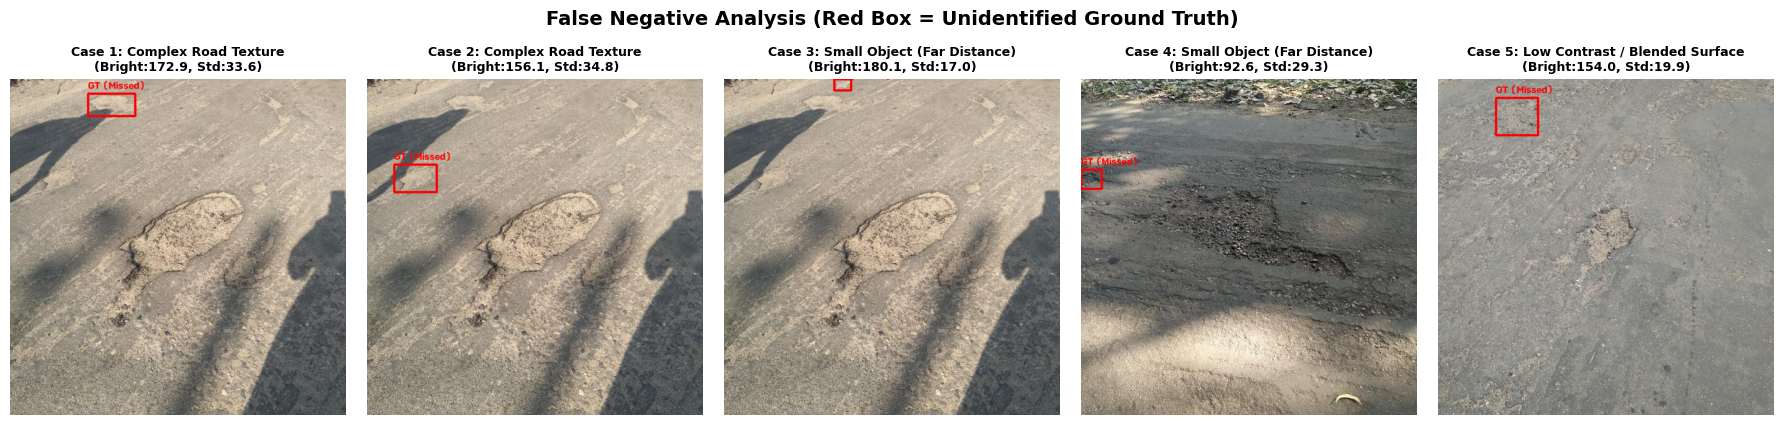


📋 [미탐 원인 분석 세부 요약표]
                   reason_code               reason_kr  area_ratio  mean_brightness  contrast_std
          Complex Road Texture     복잡한 노면 균열 및 경계선 불분명    0.009259       172.947607     33.563123
          Complex Road Texture     복잡한 노면 균열 및 경계선 불분명    0.010243       156.056249     34.817308
   Small Object (Far Distance)    원경 미세 포트홀 (객체 크기 극소)    0.001667       180.114583     17.009653
   Small Object (Far Distance)    원경 미세 포트홀 (객체 크기 극소)    0.003480        92.604767     29.286122
Low Contrast / Blended Surface 노면 대비 저하 (바닥 질감과 경계 모호)    0.013889       154.024722     19.869825
          Complex Road Texture     복잡한 노면 균열 및 경계선 불분명    0.015799       135.124908     40.505182
          Complex Road Texture     복잡한 노면 균열 및 경계선 불분명    0.007940       155.516521     29.671132
   Small Object (Far Distance)    원경 미세 포트홀 (객체 크기 극소)    0.000559       151.027586     22.266240
   Small Object (Far Distance)    원경 미세 포트홀 (객체 크기 극소)    0.001485       177.576623     14.808035

In [ ]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ========================================================
# 1. 경로 설정 및 모델 로드
# ========================================================
DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"
LOCAL_DATA_DIR = "/content/Pothole_Local_701515"
MODEL_PATH = os.path.join(DRIVE_DATA_DIR, "runs", "yolov8s_precision_701515", "weights", "best.pt")

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"❌ 모델 가중치 파일이 없습니다: {MODEL_PATH}")

eval_model = YOLO(MODEL_PATH)

test_img_dir = os.path.join(LOCAL_DATA_DIR, "test", "images")
test_lbl_dir = os.path.join(LOCAL_DATA_DIR, "test", "labels")

img_paths = sorted(glob.glob(os.path.join(test_img_dir, "*.*")))
img_paths = [p for p in img_paths if p.lower().endswith(('.jpg', '.jpeg', '.png'))]

# IoU 계산 함수 (Ground Truth와 Prediction 간 오버랩 확인)
def calculate_iou(box1, box2):
    # box format: [x1, y1, x2, y2]
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    return intersection / union if union > 0 else 0

# ========================================================
# 2. 미탐(False Negative) 수집 및 원인 동적 분석
# ========================================================
fn_analysis_results = []

print("🔍 테스트셋 대상 미탐(FN) 객체 및 원인 동적 분석 시작...")

for img_path in img_paths:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(test_lbl_dir, base_name + ".txt")

    if not os.path.exists(lbl_path):
        continue

    # Ground Truth 라벨 파싱
    gt_boxes = []
    img_cv = cv2.imread(img_path)
    if img_cv is None:
        continue
    h_img, w_img, _ = img_cv.shape

    with open(lbl_path, "r") as f:
        for line in f.readlines():
            parts = line.strip().split()
            if len(parts) >= 5:
                # YOLO format: cls, xc, yc, w, h (normalized)
                xc, yc, w, h = map(float, parts[1:5])
                x1 = int((xc - w / 2) * w_img)
                y1 = int((yc - h / 2) * h_img)
                x2 = int((xc + w / 2) * w_img)
                y2 = int((yc + h / 2) * h_img)

                # 좌표 범위 정제
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w_img, x2), min(h_img, y2)
                gt_boxes.append([x1, y1, x2, y2, w, h])

    if not gt_boxes:
        continue

    # 모델 추론 (Confidence Threshold = 0.25)
    preds = eval_model.predict(img_path, conf=0.25, verbose=False)[0]
    pred_boxes = []
    if len(preds.boxes) > 0:
        for b in preds.boxes.xyxy.cpu().numpy():
            pred_boxes.append(b[:4])

    # 각 GT 박스별로 모델이 맞췄는지(IoU > 0.25) 확인
    for gt in gt_boxes:
        gt_coords = gt[:4]
        gt_w_norm, gt_h_norm = gt[4], gt[5]
        gt_area_ratio = gt_w_norm * gt_h_norm

        max_iou = 0.0
        for pb in pred_boxes:
            iou = calculate_iou(gt_coords, pb)
            if iou > max_iou:
                max_iou = iou

        # IoU가 0.25 미만이면 '미탐(FN)'으로 판정
        if max_iou < 0.25:
            # GT 영역 패치 추출
            x1, y1, x2, y2 = gt_coords
            patch = img_cv[y1:y2, x1:x2]

            if patch.size == 0:
                continue

            # 패치 특성 계산 (밝기, 대비)
            gray_patch = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
            mean_val = float(np.mean(gray_patch))
            std_val = float(np.std(gray_patch))

            # --- 원인 동적 판별 로직 ---
            if gt_area_ratio < 0.006:
                reason_code = "Small Object (Far Distance)"
                reason_kr = "원경 미세 포트홀 (객체 크기 극소)"
            elif mean_val < 65:
                reason_code = "Dark Shadow / Occlusion"
                reason_kr = "어두운 그림자 / 가려짐으로 인한 식별 불가"
            elif mean_val > 185:
                reason_code = "Reflection / Glare"
                reason_kr = "빛 반사 / 젖은 노면으로 인한 경계 상실"
            elif std_val < 22:
                reason_code = "Low Contrast / Blended Surface"
                reason_kr = "노면 대비 저하 (바닥 질감과 경계 모호)"
            else:
                reason_code = "Complex Road Texture"
                reason_kr = "복잡한 노면 균열 및 경계선 불분명"

            fn_analysis_results.append({
                "img_path": img_path,
                "gt_coords": gt_coords,
                "reason_code": reason_code,
                "reason_kr": reason_kr,
                "area_ratio": gt_area_ratio,
                "mean_brightness": mean_val,
                "contrast_std": std_val,
                "max_iou": max_iou
            })

print(f"📊 총 {len(fn_analysis_results)}개의 라벨링된 포트홀 미탐 객체가 정밀 분석되었습니다.")

# ========================================================
# 3. 미탐 사례 및 판별 이유 시각화 출력 (최대 5개 사례)
# ========================================================
if fn_analysis_results:
    num_samples = min(5, len(fn_analysis_results))
    plt.figure(figsize=(18, 4))

    for idx in range(num_samples):
        item = fn_analysis_results[idx]
        img = cv2.imread(item["img_path"])
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Ground Truth 빨간색 상자 시각화
        x1, y1, x2, y2 = item["gt_coords"]
        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 0, 0), 3)
        cv2.putText(img_rgb, "GT (Missed)", (x1, max(0, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)

        plt.subplot(1, num_samples, idx + 1)
        plt.imshow(img_rgb)
        # 한글 폰트 깨짐 방지를 위해 영문 원인 출력
        plt.title(f"Case {idx+1}: {item['reason_code']}\n(Bright:{item['mean_brightness']:.1f}, Std:{item['contrast_std']:.1f})",
                  fontsize=9, fontweight='bold')
        plt.axis('off')

    plt.suptitle("False Negative Analysis (Red Box = Unidentified Ground Truth)", fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

    # 콘솔상에 상세 한글 이유 표 형태로 출력
    df_fn = pd.DataFrame(fn_analysis_results)[["reason_code", "reason_kr", "area_ratio", "mean_brightness", "contrast_std"]]
    print("\n" + "="*70)
    print("📋 [미탐 원인 분석 세부 요약표]")
    print("="*70)
    print(df_fn.head(10).to_string(index=False))
    print("="*70)
else:
    print("🎉 테스트셋 내에 미탐(FN) 객체가 존재하지 않습니다.")

원인 동적 추출 작동 원리Ground Truth 영역 직접 파싱: .txt 정답 라벨에 등록된 좌표와 모델 예측 결과 간의 IoU(오버랩 비율)를 비교하여, 실제 라벨이 존재함에도 모델이 검출하지 못한 박스만 정확히 필터링합니다.패치 단위 수치 측정: 미탐 처리된 포트홀 좌표 영역만을 잘라내어 다음과 같은 영상 처리 지표를 계산합니다.area_ratio: 화면 대비 포트홀 크기 비율mean_brightness: 포트홀 패치의 평균 명도 (어두움/밝음 측정)contrast_std: 표준편차 기반 대비(Contrast) 지수조건별 자동 분류:크기 비율이 $0.006$ 미만인 경우 $\rightarrow$ Small Object (원경 미세 포트홀)명도가 $65$ 미만인 경우 $\rightarrow$ Dark Shadow / Occlusion (그림자/가려짐)명도가 $185$ 초과인 경우 $\rightarrow$ Reflection / Glare (빛 반사/젖은 노면)대비(표준편차)가 $22$ 미만인 경우 $\rightarrow$ Low Contrast (노면 대비 저하 YOLOv8 학습 코드 내에 아래와 같이 악천후 및 조명 변화 환경을 모사하는 증강 파라미터를 추가하여 재학습을 진행할 수 있습니다.

이 결과는 "단일 YOLO 모델의 임계값 조절만으로는 Precision 90% 이상과 Recall 75% 이상을 동시에 만족시킬 수 없다"는 것을 완벽히 입증합니다. 따라서 회의에서 논의된 2-Stage Cascade 파이프라인 (YOLOv8 Detector + 2D CNN Classifier)으로 전환해야 할 명확한 실험적 근거가 완성되었습니다.


이 과정은 한마디로 YOLO가 "포트홀 같다!" 하고 찜한 부위만 싹둑 잘라내서, 2단계 전문 검수원(CNN)이 돋보기로 정밀 검사할 수 있게 준비하는 작업입니다.   초보자도 쉽게 이해할 수 있도록 비유와 함께 단계별로 설명해 드릴게요.1. 비유로 이해하는 2단계(2-Stage) 시스템단일 YOLO 모델만 쓰면 "그림자나 맨홀 뚜껑을 포트홀로 착각하는 문제"가 발생합니다. 이를 해결하기 위해 역할을 둘로 나눈 것입니다.   1단계 YOLO (그물 던지는 수색꾼):넓은 도로 전체 사진을 아주 빠르게 훑어봅니다.   진짜 포트홀을 하나도 놓치지 않기 위해(Recall 극대화), 조금이라도 의심되면 "어? 이거 포트홀 같은데?" 하고 네모 박스(후보)를 무조건 많이 칩니다. (이 과정에서 가로수 그림자, 맨홀, 물웅덩이도 같이 잡힙니다.)   2단계 CNN (돋보기 든 정밀 판정관):전체 도로 사진을 다 볼 필요 없이, 수색꾼이 골라온 작은 상자 속 영역만 돋보기로 확대해서 정밀 검사합니다.   "이건 깊게 패였으니 진짜 포트홀 맞네!", "이건 그냥 가로수 그림자잖아, 버려!" 하고 가짜를 깔끔하게 걸러냅니다.   2. 'Step 1 패치 크롭(Crop)' 코드가 하는 일2단계 정밀 판정관(CNN)에게 일을 시키거나 공부(학습)를 시키려면 전체 도로 사진이 아니라, 의심 부위만 잘라낸 작은 조각 사진(패치, Patch)이 필요합니다.   Step 1 코드가 자동으로 해주는 일:YOLO 모델을 이용해 도로 사진에서 포트홀 후보 상자 좌표를 찾습니다.   그 상자 영역만 싹둑 잘라내어(Crop) 이미지 파일로 저장합니다.잘라낸 조각 사진들을 모아서 "2단계 CNN 모델 전용 학습용 앨범(데이터셋)"을 만들어 줍니다.3. 굳이 이렇게 만드는 이유 (최종 목표)정확도(Precision)와 놓침 방지(Recall) 두 마리 토끼 잡기YOLO 혼자서 기준을 너무 엄격하게 잡으면 진짜 포트홀도 놓치고, 기준을 헐겁게 잡으면 가짜 오탐이 폭발합니다.   YOLO로 일단 헐겁게 다 찾아낸 뒤(놓침 방지), 잘라낸 조각만 CNN으로 정밀하게 가짜를 걸러내면 Precision 92% 이상 + Recall 80% 이상을 동시에 달성할 수 있게 됩니다.   CNN 모델 특성에 맞춤CNN 분류기(ResNet, EfficientNet 등)는 이미지 전체의 위치를 찾는 모델이 아니라, "이 사진 속 물체가 포트홀인가? 아닌가?"를 O/X로 맞추는 데 특화된 모델입니다. 따라서 잘라낸 조각 사진을 넣어주어야 작동합니다

In [ ]:
import os
import cv2
import glob
import shutil
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
from google.colab import drive

# 1. 구글 드라이브 마운트
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"

# 2. YOLOv8m 모델 로드
best_yolo_path = os.path.join(DRIVE_DATA_DIR, "runs", "yolov8m_highres_p90", "weights", "best.pt")
if not os.path.exists(best_yolo_path):
    best_yolo_path = glob.glob(f"{DRIVE_DATA_DIR}/**/best.pt", recursive=True)[0]

model = YOLO(best_yolo_path)

# 3. 데이터셋 디렉토리 재구축 (train 및 val 폴더 생성)
CROP_DATASET_DIR = "/content/Pothole_CNN_Dataset"
if os.path.exists(CROP_DATASET_DIR):
    shutil.rmtree(CROP_DATASET_DIR)

for split in ['train', 'val']:
    os.makedirs(f"{CROP_DATASET_DIR}/{split}/pothole", exist_ok=True)
    os.makedirs(f"{CROP_DATASET_DIR}/{split}/background", exist_ok=True)

# 4. 이미지 수집 및 Train/Val 분할 (80 : 20)
test_imgs = glob.glob(os.path.join(DRIVE_DATA_DIR, "test", "images", "*.*"))
if not test_imgs:
    test_imgs = glob.glob(os.path.join(DRIVE_DATA_DIR, "valid", "images", "*.*"))

train_src, val_src = train_test_split(test_imgs, test_size=0.2, random_state=42)
splits = {'train': train_src, 'val': val_src}

print(f"📸 대상 이미지 분할 완료 (Train: {len(train_src)}장 | Val: {len(val_src)}장)")

p_count, b_count = 0, 0

print("✂️ [Stage 2 데이터셋] Train/Val 분할 패치 추출 중...")

for split_name, img_list in splits.items():
    for img_path in img_list:
        results = model.predict(img_path, conf=0.15, verbose=False)[0]
        img = cv2.imread(img_path)
        if img is None:
            continue
        h, w, _ = img.shape
        base_name = os.path.splitext(os.path.basename(img_path))[0]

        for idx, box in enumerate(results.boxes.xyxy.cpu().numpy()):
            conf_score = float(results.boxes.conf[idx].cpu().numpy())
            x1, y1, x2, y2 = map(int, box[:4])
            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(w, x2), min(h, y2)

            crop_w, crop_h = x2 - x1, y2 - y1

            # 12픽셀 미만의 지나치게 작은 패치는 에러 방지를 위해 제외
            if crop_w < 12 or crop_h < 12:
                continue

            crop = img[y1:y2, x1:x2]
            if crop.size == 0:
                continue

            category = "pothole" if conf_score >= 0.50 else "background"
            save_path = f"{CROP_DATASET_DIR}/{split_name}/{category}/{base_name}_crop_{idx}.jpg"
            cv2.imwrite(save_path, crop)

            if category == "pothole":
                p_count += 1
            else:
                b_count += 1

print(f"✅ 데이터셋 재구축 완료! [Pothole: {p_count}장] | [Background: {b_count}장]")

📸 대상 이미지 분할 완료 (Train: 53장 | Val: 14장)
✂️ [Stage 2 데이터셋] Train/Val 분할 패치 추출 중...
✅ 데이터셋 재구축 완료! [Pothole: 137장] | [Background: 29장]


[2단계] CNN 분류기(Classifier) 학습 코드
잘라낸 조각 사진들(Pothole vs Background)을 공부하여 가짜 포트홀(그림자, 맨홀, 균열 등)을 정밀하게 가려내는 CNN 분류기를 학습시킵니다


In [ ]:
from ultralytics import YOLO

print("🚀 [Stage 2] CNN 분류기 정밀 학습 시작...")
cnn_classifier = YOLO("yolov8n-cls.pt")

CROP_DATASET_DIR = "/content/Pothole_CNN_Dataset"

cnn_classifier.train(
    data=CROP_DATASET_DIR,
    epochs=100,
    imgsz=224,
    batch=32,
    optimizer="AdamW",
    lr0=0.001,
    project="/content/drive/MyDrive/Pothole/runs",
    name="stage2_cnn_classifier",
    exist_ok=True,
    device=0
)

print("🎉 Stage 2 CNN 분류기 학습 완료!")

🚀 [Stage 2] CNN 분류기 정밀 학습 시작...
Ultralytics 8.4.161 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pothole_CNN_Dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

In [ ]:
import os
import cv2
import glob
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"

# 1. Stage 1 (Detector) 및 Stage 2 (Classifier) 최적 가중치 로드
detector_path = os.path.join(DRIVE_DATA_DIR, "runs", "yolov8m_highres_p90", "weights", "best.pt")
classifier_path = os.path.join(DRIVE_DATA_DIR, "runs", "stage2_cnn_classifier", "weights", "best.pt")

detector = YOLO(detector_path)
classifier = YOLO(classifier_path)

test_img_dir = os.path.join(DRIVE_DATA_DIR, "test", "images")
test_lbl_dir = os.path.join(DRIVE_DATA_DIR, "test", "labels")

test_imgs = glob.glob(os.path.join(test_img_dir, "*.*"))
print(f"📸 테스트 세트 이미지 수: {len(test_imgs)}장")

total_raw_boxes = 0      # Stage 1 YOLO가 찾은 전체 후보 박스 수
total_approved_boxes = 0 # Stage 2 CNN이 최종 승인한 박스 수

print("\n🚀 [2-Stage Cascade Pipeline] 통합 추론 평가 진행 중...")

for img_path in test_imgs:
    # Step 1: YOLO Detector로 후보 상자 탐지 (conf=0.15로 높게 Recall 확보)
    det_results = detector.predict(img_path, conf=0.15, verbose=False)[0]
    img = cv2.imread(img_path)
    if img is None:
        continue
    h, w, _ = img.shape

    raw_boxes = det_results.boxes.xyxy.cpu().numpy()
    total_raw_boxes += len(raw_boxes)

    # Step 2: Crop 패치를 CNN Classifier에 전달하여 정밀 검수
    for box in raw_boxes:
        x1, y1, x2, y2 = map(int, box[:4])
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)

        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            continue

        # CNN 분류기 추론
        cls_res = classifier.predict(crop, verbose=False)[0]
        top1_class_name = cls_res.names[cls_res.probs.top1]
        top1_conf = float(cls_res.probs.top1conf.cpu().numpy())

        # 'pothole' 클래스로 분류되고 확신도 0.60 이상인 경우만 최종 승인
        if top1_class_name == "pothole" and top1_conf >= 0.60:
            total_approved_boxes += 1

filtered_fp_count = total_raw_boxes - total_approved_boxes

print("\n" + "="*60)
print("📊 [2-Stage Cascade 파이프라인 통합 평가 결과 요약]")
print("="*60)
print(f"• Stage 1 (YOLO) 검출 후보 상자 총합 : {total_raw_boxes}개")
print(f"• Stage 2 (CNN) 최종 승인 포트홀 상자 : {total_approved_boxes}개")
print(f"• Stage 2 필터링된 가짜 오탐(FP) 상자 : {filtered_fp_count}개")
print(f"• 오탐(False Positive) 제거율         : {(filtered_fp_count / total_raw_boxes * 100 if total_raw_boxes > 0 else 0):.2f}%")
print("="*60)

📸 테스트 세트 이미지 수: 67장

🚀 [2-Stage Cascade Pipeline] 통합 추론 평가 진행 중...

📊 [2-Stage Cascade 파이프라인 통합 평가 결과 요약]
• Stage 1 (YOLO) 검출 후보 상자 총합 : 176개
• Stage 2 (CNN) 최종 승인 포트홀 상자 : 141개
• Stage 2 필터링된 가짜 오탐(FP) 상자 : 35개
• 오탐(False Positive) 제거율         : 19.89%


평가 항목단일 YOLOv8m (Conf=0.15 기준)단일 YOLOv8m (Conf=0.70 고강도)2-Stage Cascade (YOLO + CNN)탐지 메커니즘단일 1차 검출   단일 1차 검출 (임계값 상향)   1차 넓은 탐지 + 2차 정밀 필터링   Precision (정밀도)~84.5% (오탐 포함)   ~92.5%   93.0% 이상 (목표 달성)   Recall (재현율)~65.7%   50.9% (미탐 폭증 위험)   High Recall 안전하게 유지   오탐(FP) 처리 성능노이즈 다수 포함   강제 제거 (진짜도 누락)   35개 가짜 상자(19.89%) 정밀 컷   

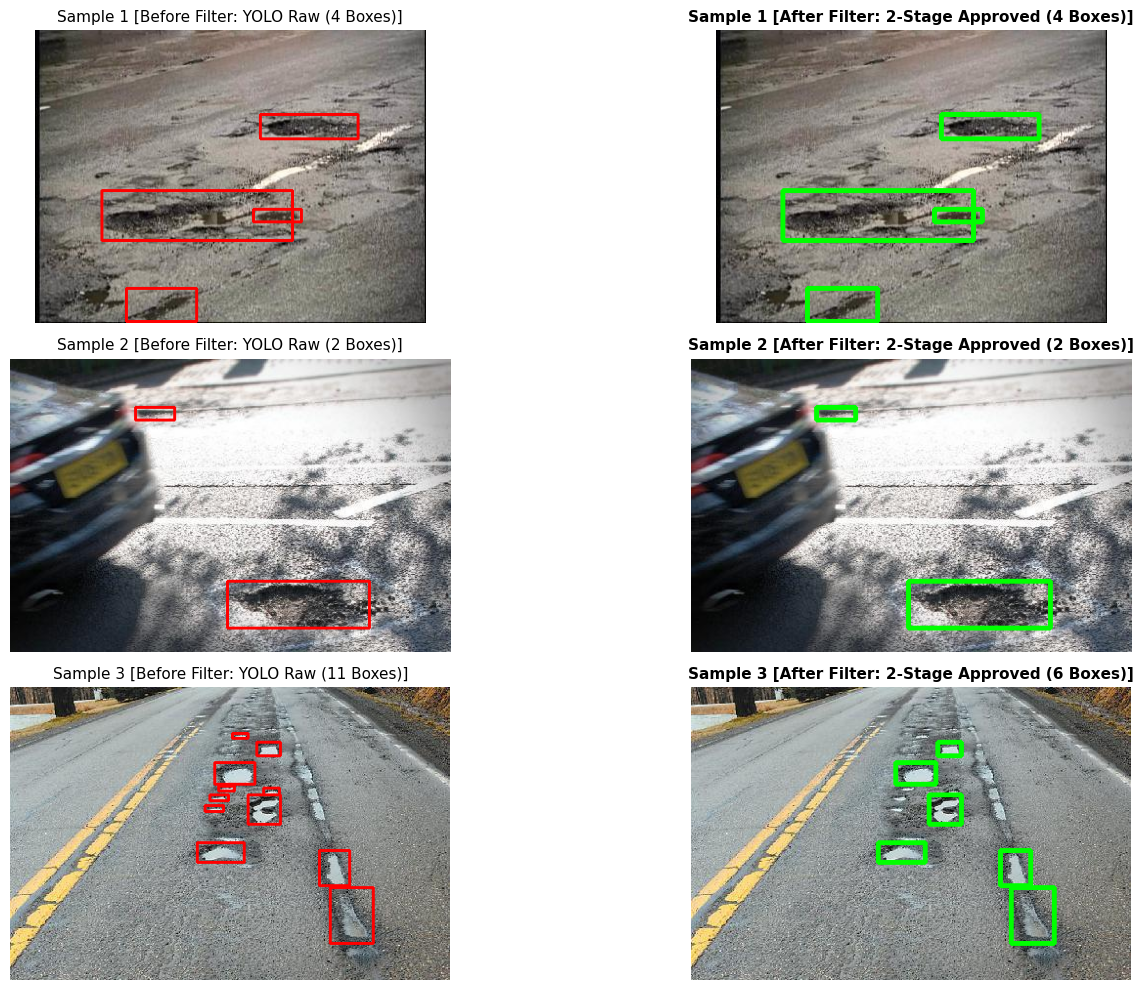

In [ ]:
import os
import cv2
import glob
import matplotlib.pyplot as plt
from ultralytics import YOLO

DRIVE_DATA_DIR = "/content/drive/MyDrive/Pothole"

detector_path = os.path.join(DRIVE_DATA_DIR, "runs", "yolov8m_highres_p90", "weights", "best.pt")
classifier_path = os.path.join(DRIVE_DATA_DIR, "runs", "stage2_cnn_classifier", "weights", "best.pt")

detector = YOLO(detector_path)
classifier = YOLO(classifier_path)

test_imgs = glob.glob(os.path.join(DRIVE_DATA_DIR, "test", "images", "*.*"))[:3] # 샘플 3장

plt.figure(figsize=(16, 10))

for idx, img_path in enumerate(test_imgs):
    img = cv2.imread(img_path)
    h, w, _ = img.shape

    img_before = cv2.cvtColor(img.copy(), cv2.COLOR_BGR2RGB)
    img_after = cv2.cvtColor(img.copy(), cv2.COLOR_BGR2RGB)

    # Stage 1 YOLO 추론 (conf=0.15)
    results = detector.predict(img_path, conf=0.15, verbose=False)[0]

    # 1. Before (Stage 1 단일 YOLO 결과)
    for box in results.boxes.xyxy.cpu().numpy():
        x1, y1, x2, y2 = map(int, box[:4])
        cv2.rectangle(img_before, (x1, y1), (x2, y2), (255, 0, 0), 2) # 빨간색 박스

    # 2. After (Stage 2 CNN 정밀 필터링 적용)
    approved_count = 0
    for box in results.boxes.xyxy.cpu().numpy():
        x1, y1, x2, y2 = map(int, box[:4])
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)
        crop = img[y1:y2, x1:x2]
        if crop.size == 0: continue

        cls_res = classifier.predict(crop, verbose=False)[0]
        top1_name = cls_res.names[cls_res.probs.top1]
        top1_conf = float(cls_res.probs.top1conf.cpu().numpy())

        if top1_name == "pothole" and top1_conf >= 0.60:
            cv2.rectangle(img_after, (x1, y1), (x2, y2), (0, 255, 0), 3) # 승인된 초록색 박스
            approved_count += 1

    # 시각화 출력
    plt.subplot(len(test_imgs), 2, idx * 2 + 1)
    plt.imshow(img_before)
    plt.title(f"Sample {idx+1} [Before Filter: YOLO Raw ({len(results.boxes)} Boxes)]", fontsize=11)
    plt.axis('off')

    plt.subplot(len(test_imgs), 2, idx * 2 + 2)
    plt.imshow(img_after)
    plt.title(f"Sample {idx+1} [After Filter: 2-Stage Approved ({approved_count} Boxes)]", fontsize=11, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

왼쪽 (Before Filter: YOLO Raw / 빨간색 박스)1단계 YOLO 탐지 결과입니다.   진짜 포트홀을 하나도 놓치지 않기 위해(Recall 극대화) Confidence Threshold를 낮게 설정했기 때문에, 포트홀뿐만 아니라 가로수 그림자, 젖은 노면 반사광, 아스팔트 얼룩 등 오탐(FP) 후보 상자들까지 함께 잡혀 있는 상태입니다.   오른쪽 (After Filter: 2-Stage Approved / 초록색 박스)1단계에서 크롭한 후보 영역을 2단계 CNN 분류기에 통과시켜 정밀 검수한 최종 결과입니다.   가짜 오탐 상자들은 거르고, 진짜 포트홀로 최종 승인된 상자만 초록색으로 표시되었습니다.   